<a href="https://colab.research.google.com/github/brendharosa/primeiro1/blob/main/Projeto_Clima_Horizontina_API.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coleta e Análise de Dados Meteorológicos de Horizontina - RS

**Objetivo:** Desenvolver uma aplicação em Python para coletar automaticamente dados meteorológicos por meio da API pública Open-Meteo, organizar as informações e armazená-las em arquivos CSV e JSON.

**Fonte dos dados:** https://open-meteo.com/

In [27]:
# Importando as bibliotecas

import requests
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np

print("Biblotecas importadas com sucesso!")

Biblotecas importadas com sucesso!


In [28]:

# Endereço da API Open-Meteo
url = "https://api.open-meteo.com/v1/forecast"

# Coordenadas de Horizontina - RS
latitude = -27.6258
longitude = -54.3078

# Parâmetros da consulta
parametros = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "timezone": "America/Sao_Paulo",
    "forecast_days": 7
}

# Realizando a requisição
resposta = requests.get(url, params=parametros, timeout=20)

# Verificando a resposta da API
print("Código de resposta:", resposta.status_code)

if resposta.status_code == 200:
    print("Conexão realizada com sucesso!")
else:
    print("Erro ao acessar a API.")


Código de resposta: 200
Conexão realizada com sucesso!


In [29]:

# Convertendo a resposta da API para JSON
dados = resposta.json()

# Obtendo as informações meteorológicas
clima = dados["hourly"]

# Separando os dados recebidos
datas = clima["time"]
temperaturas = clima["temperature_2m"]
umidades = clima["relative_humidity_2m"]
chuvas = clima["precipitation"]

# Mostrando os primeiros 5 registros
print("Dados meteorológicos de Horizontina - RS")
print("--------------------------------------")

for i in range(5):
    print("Data e hora:", datas[i])
    print("Temperatura:", temperaturas[i], "°C")
    print("Umidade:", umidades[i], "%")
    print("Precipitação:", chuvas[i], "mm")
    print("--------------------------------------")


Dados meteorológicos de Horizontina - RS
--------------------------------------
Data e hora: 2026-11-14T00:00
Temperatura: 23.8 °C
Umidade: 68 %
Precipitação: 0.0 mm
--------------------------------------
Data e hora: 2026-11-14T01:00
Temperatura: 22.7 °C
Umidade: 74 %
Precipitação: 0.0 mm
--------------------------------------
Data e hora: 2026-11-14T02:00
Temperatura: 21.8 °C
Umidade: 79 %
Precipitação: 0.0 mm
--------------------------------------
Data e hora: 2026-11-14T03:00
Temperatura: 21.8 °C
Umidade: 77 %
Precipitação: 0.0 mm
--------------------------------------
Data e hora: 2026-11-14T04:00
Temperatura: 21.5 °C
Umidade: 77 %
Precipitação: 0.0 mm
--------------------------------------


In [30]:
# Importando as bibliotecas
import requests
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np

# Criando a tabela
tabela_clima = {
    "Data e Hora": datas,
    "Temperatura (°C)": temperaturas,
    "Umidade (%)": umidades,
    "Precipitação (mm)": chuvas
}

# Transformando os dados em um DataFrame
df = pd.DataFrame(tabela_clima)

# Exibindo os primeiros 10 registros
print("Dados meteorológicos de Horizontina - RS")
display(df.head(10))

Dados meteorológicos de Horizontina - RS


,Data e Hora,Temperatura (°C),Umidade (%),Precipitação (mm)
0,2026-11-14T00:00,23.8,68,0.0
1,2026-11-14T01:00,22.7,74,0.0
2,2026-11-14T02:00,21.8,79,0.0
3,2026-11-14T03:00,21.8,77,0.0
4,2026-11-14T04:00,21.5,77,0.0
5,2026-11-14T05:00,20.9,81,0.0
6,2026-11-14T06:00,21.1,83,0.0
7,2026-11-14T07:00,22.9,78,0.0
8,2026-11-14T08:00,24.8,76,0.0
9,2026-11-14T09:00,26.6,73,0.0


In [31]:

# Mostrando a quantidade de linhas e colunas
print("Quantidade de linhas e colunas:")
print(df.shape)



Quantidade de linhas e colunas:
(168, 4)


In [32]:

# Salvando os dados em CSV
df.to_csv("clima_horizontina.csv", index=False)

# Salvando os dados em JSON
df.to_json(
    "clima_horizontina.json",
    orient="records",
    indent=4,
    force_ascii=False
)

# Mensagem de confirmação
print("Arquivos salvos com sucesso!")
print("CSV: clima_horizontina.csv")
print("JSON: clima_horizontina.json")


Arquivos salvos com sucesso!
CSV: clima_horizontina.csv
JSON: clima_horizontina.json


In [19]:

# Importando a ferramenta de download do Colab
from google.colab import files

# Baixando os arquivos
files.download("clima_horizontina.csv")
files.download("clima_horizontina.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

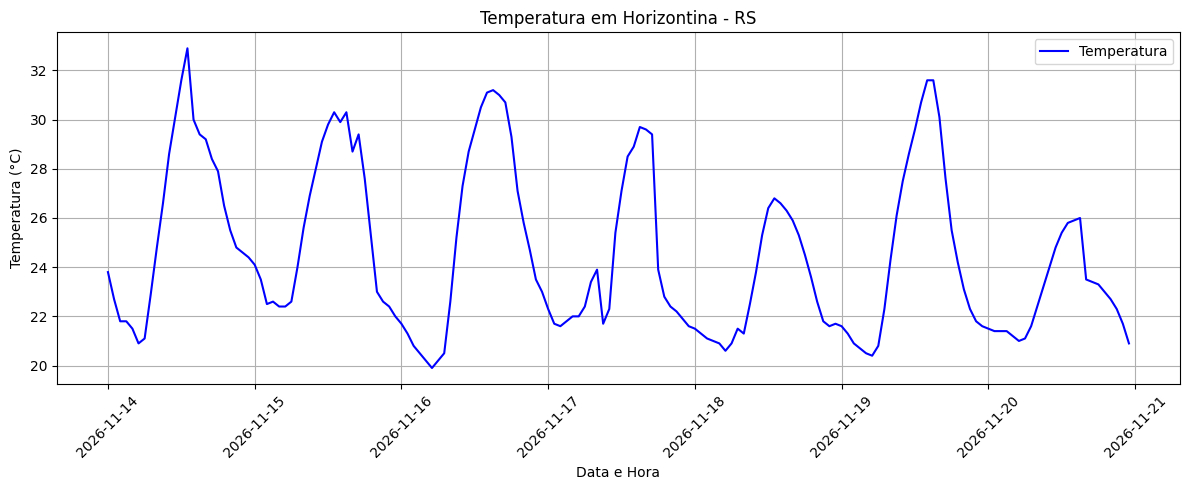

In [33]:

# Convertendo a coluna de datas
df["Data e Hora"] = pd.to_datetime(df["Data e Hora"])

# Criando o gráfico
plt.figure(figsize=(12, 5))

# Gráfico de linhas da temperatura
plt.plot(
    df["Data e Hora"],
    df["Temperatura (°C)"],
    color="blue",
    label="Temperatura"
)

# Título e identificação dos eixos
plt.title("Temperatura em Horizontina - RS")
plt.xlabel("Data e Hora")
plt.ylabel("Temperatura (°C)")

# Configurações do gráfico
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()

# Exibindo o gráfico
plt.savefig("grafico_temperatura.png")
plt.show()


## Conclusão

O projeto permitiu coletar automaticamente dados meteorológicos de Horizontina (RS) utilizando Python e a API Open-Meteo. Os dados foram organizados com Pandas, salvos em CSV e JSON e apresentados em um gráfico com Matplotlib, assim, atendendo aos objetivos da atividade.